You are a data analyst working for a tech company closely monitoring the AI tools market. You want to understand the evolving popularity of three major AI tools, ChatGPT, Gemini, and Microsoft Copilot, and identify which tool is gaining the most traction and how they compare over time.


<img src="ai_tools.jpg" align="center"/>

You'll work with real-world time series data that captures the global interest in these tools over several weeks. Your goal is to analyze this data, uncover patterns, and provide actionable insights to help your company make informed decisions. This might include determining where to focus marketing efforts, predicting future trends, or identifying potential areas for improvement.

Are you ready to help your company stay ahead of the curve in the competitive AI tools market? Let's get started!

### The Data

The Google Trends data is available as a CSV file `ai_tools_comparison.csv`.
The data contains the number of worldwide searches for chatGpt, Gemini, and Microsoft Copilot over the past 12 months as of September 2024. 
<!--- Link to query: https://trends.google.com/trends/explore?q=chatgpt,gemini,%2Fg%2F11tsqm45vd&hl=en-US -->

In [79]:
import pandas as pd
import matplotlib.pyplot as plt

# Load the data
trends = pd.read_csv('ai_tools_comparison.csv')

# Inspect the data
print(trends.head())
print(trends.info())

         week  chatgpt  gemini  microsoft_copilot
0  2023-08-27       56       3                  1
1  2023-09-03       56       3                  1
2  2023-09-10       63       3                  1
3  2023-09-17       64       3                  1
4  2023-09-24       66       3                  1
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 54 entries, 0 to 53
Data columns (total 4 columns):
 #   Column             Non-Null Count  Dtype 
---  ------             --------------  ----- 
 0   week               54 non-null     object
 1   chatgpt            54 non-null     int64 
 2   gemini             54 non-null     int64 
 3   microsoft_copilot  54 non-null     int64 
dtypes: int64(3), object(1)
memory usage: 1.8+ KB
None


For starters, we see that the number of non-nulls per column matches the number of entries in the dataset, so we don't need to worry about handling N/As.

We see that the `week` column has the `object` datatype. Since the data in its column are evidently dates, we would want to convert this to the `datetime64[ns]` datatype. To do this, we use the `.to_datetime` method.

In [80]:
trends['week'] = pd.to_datetime(trends['week'])
print(trends.head())
print(trends.info())

        week  chatgpt  gemini  microsoft_copilot
0 2023-08-27       56       3                  1
1 2023-09-03       56       3                  1
2 2023-09-10       63       3                  1
3 2023-09-17       64       3                  1
4 2023-09-24       66       3                  1
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 54 entries, 0 to 53
Data columns (total 4 columns):
 #   Column             Non-Null Count  Dtype         
---  ------             --------------  -----         
 0   week               54 non-null     datetime64[ns]
 1   chatgpt            54 non-null     int64         
 2   gemini             54 non-null     int64         
 3   microsoft_copilot  54 non-null     int64         
dtypes: datetime64[ns](1), int64(3)
memory usage: 1.8 KB
None


Furthermore, let's index the `DataFrame` by `week` to make indexing easier.

In [81]:
trends.set_index('week', inplace=True)
print(trends.head())
print(trends.info())

            chatgpt  gemini  microsoft_copilot
week                                          
2023-08-27       56       3                  1
2023-09-03       56       3                  1
2023-09-10       63       3                  1
2023-09-17       64       3                  1
2023-09-24       66       3                  1
<class 'pandas.core.frame.DataFrame'>
DatetimeIndex: 54 entries, 2023-08-27 to 2024-09-01
Data columns (total 3 columns):
 #   Column             Non-Null Count  Dtype
---  ------             --------------  -----
 0   chatgpt            54 non-null     int64
 1   gemini             54 non-null     int64
 2   microsoft_copilot  54 non-null     int64
dtypes: int64(3)
memory usage: 1.7 KB
None


Now, let's import `seaborn` and plot this data.

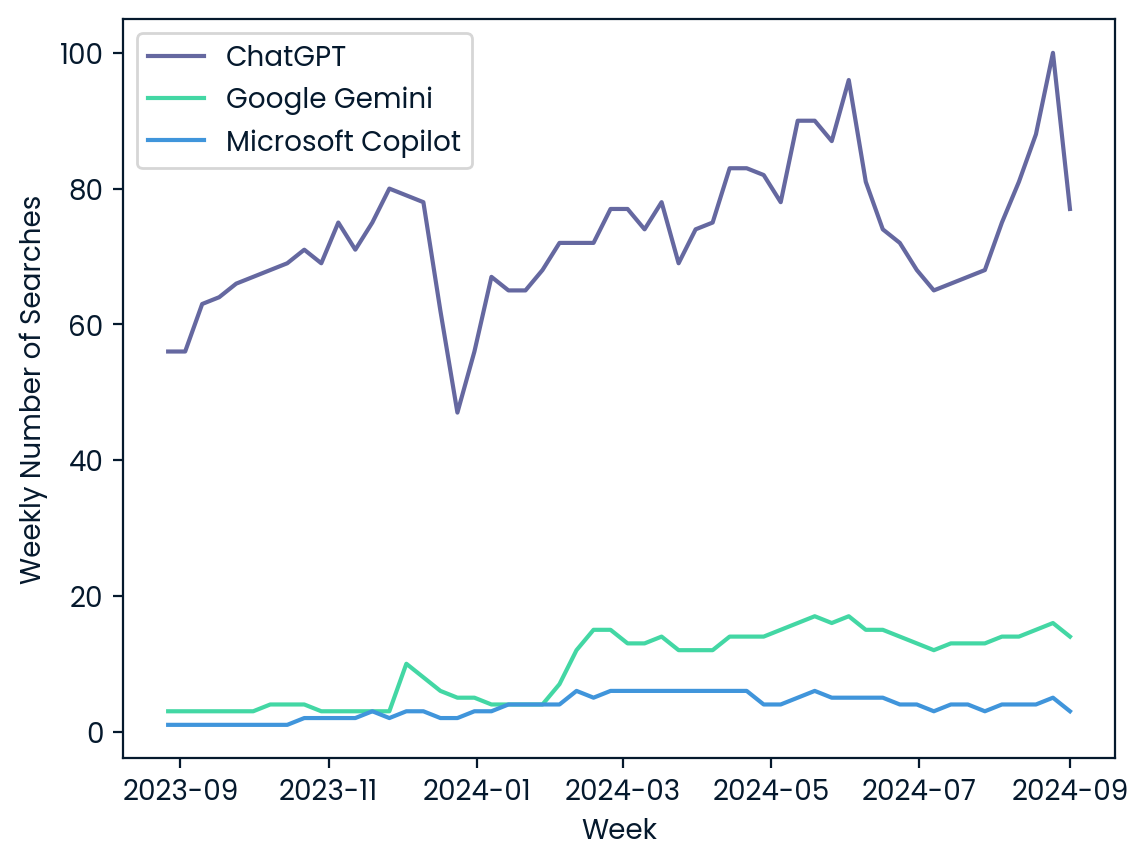

In [82]:
import seaborn as sns

sns.lineplot(data=trends, x='week', y='chatgpt', label='ChatGPT')
sns.lineplot(data=trends, x='week', y='gemini', label='Google Gemini')
sns.lineplot(data=trends, x='week', y='microsoft_copilot', label='Microsoft Copilot')
plt.xlabel('Week')
plt.ylabel('Weekly Number of Searches')
plt.legend()
plt.show()

Above we can see that ChatGPT shows significantly more interest than other LLMs, at least by the metric of searches (which is unreliable for several reasons that are beyond the scope of this project).

However, instead of looking at the absolute number of searches, let's look in how the interest changes over time by modelling each time series' percent change.

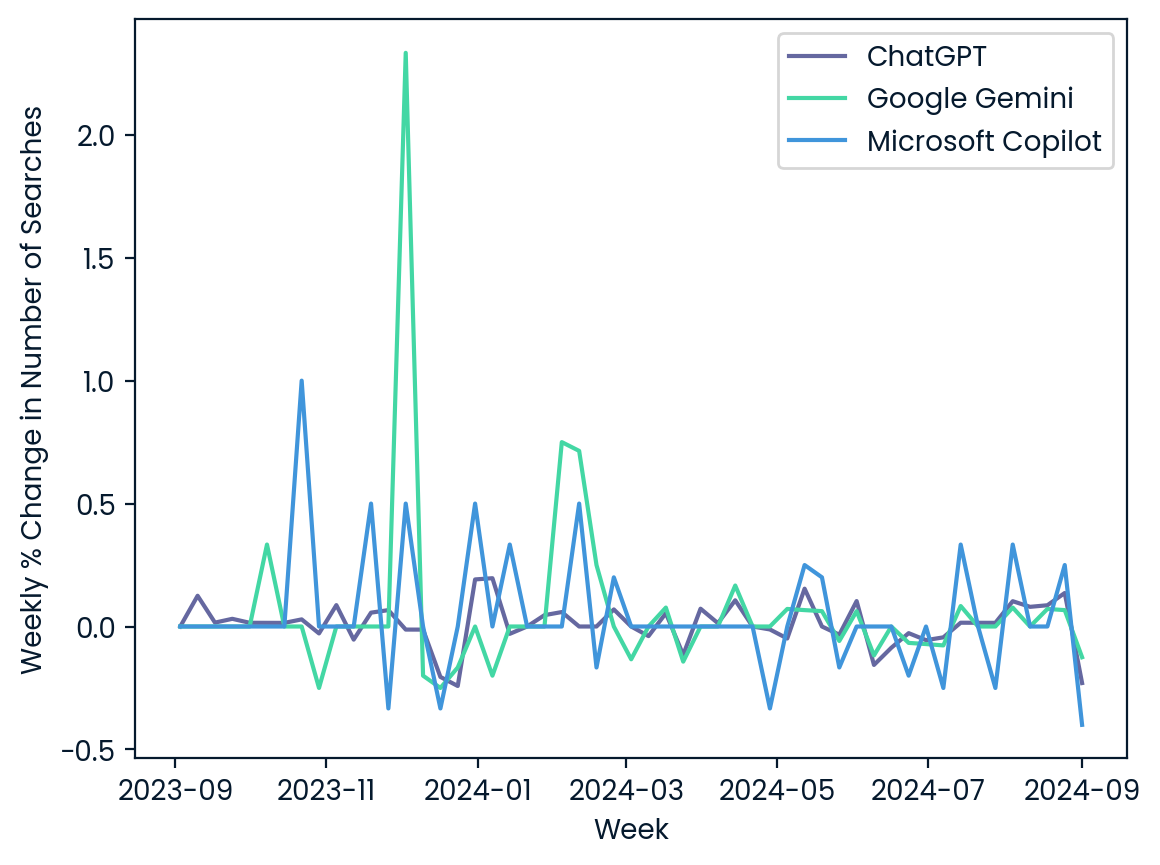

In [83]:
trends['chatgpt_pct'] = trends['chatgpt'].pct_change()
trends['gemini_pct'] = trends['gemini'].pct_change()
trends['microsoft_copilot_pct'] = trends['microsoft_copilot'].pct_change()

sns.lineplot(data=trends, x='week', y='chatgpt_pct', label='ChatGPT')
sns.lineplot(data=trends, x='week', y='gemini_pct', label='Google Gemini')
sns.lineplot(data=trends, x='week', y='microsoft_copilot_pct', label='Microsoft Copilot')
plt.xlabel('Week')
plt.ylabel('Weekly % Change in Number of Searches')
plt.legend()
plt.show()

Here we can more clearly see how interest in the three LLMs has changed over time, and we can more easily identify when exactly ChatGPT's largest dip was. But, instead of just guessing based off of a graph, we can obtain this info for ourselves.

In [84]:
gpt_dip_pct = trends['chatgpt_pct'].min()
gpt_dip_row = trends.loc[trends['chatgpt_pct'] == gpt_dip_pct]
print(gpt_dip_row)
gpt_dip = f'{gpt_dip_row.index[0]:%B %Y}'
print(gpt_dip)

            chatgpt  gemini  ...  gemini_pct  microsoft_copilot_pct
week                         ...                                   
2023-12-24       47       5  ...   -0.166667                    0.0

[1 rows x 6 columns]
December 2023


Likewise, it seems that ChatGPT has the lowest variance in percent change. This is to be expected, since ChatGPT has a higher absolute number of searches, and so small amounts of growth won't translate into massive percentage spikes. Let's verify that this is the case.

In [85]:
gpt_stdev = trends['chatgpt_pct'].std()
print(gpt_stdev)
gemini_stdev = trends['gemini_pct'].std()
print(gemini_stdev)
copilot_stdev = trends['microsoft_copilot_pct'].std()
print(copilot_stdev)

0.09051009343390698
0.3636030209722756
0.24563189249079917


ChatGPT has the lowest standard deviation in our dataset, that being 0.0905. So, we can set `most_consistent_tool` accordingly.

In [86]:
most_consistent_tool = 'ChatGPT'

Weeks are a little bit unintuitive to work with, though. The data might be clearer if we resampled the data for months instead.

We only want to resample and average the absolute numbers of searches rather than the percent changes, as those will have to be recalculated.

In [87]:
monthly_trends = trends[['chatgpt', 'gemini', 'microsoft_copilot']].resample('M').mean()
monthly_trends.index.rename('month', inplace=True)
print(monthly_trends.head())
print(monthly_trends.info())

            chatgpt  gemini  microsoft_copilot
month                                         
2023-08-31    56.00     3.0               1.00
2023-09-30    62.25     3.0               1.00
2023-10-31    68.80     3.6               1.40
2023-11-30    75.25     3.0               2.25
2023-12-31    64.40     6.8               2.60
<class 'pandas.core.frame.DataFrame'>
DatetimeIndex: 14 entries, 2023-08-31 to 2024-09-30
Freq: M
Data columns (total 3 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   chatgpt            14 non-null     float64
 1   gemini             14 non-null     float64
 2   microsoft_copilot  14 non-null     float64
dtypes: float64(3)
memory usage: 448.0 bytes
None


Let's visualize this data.

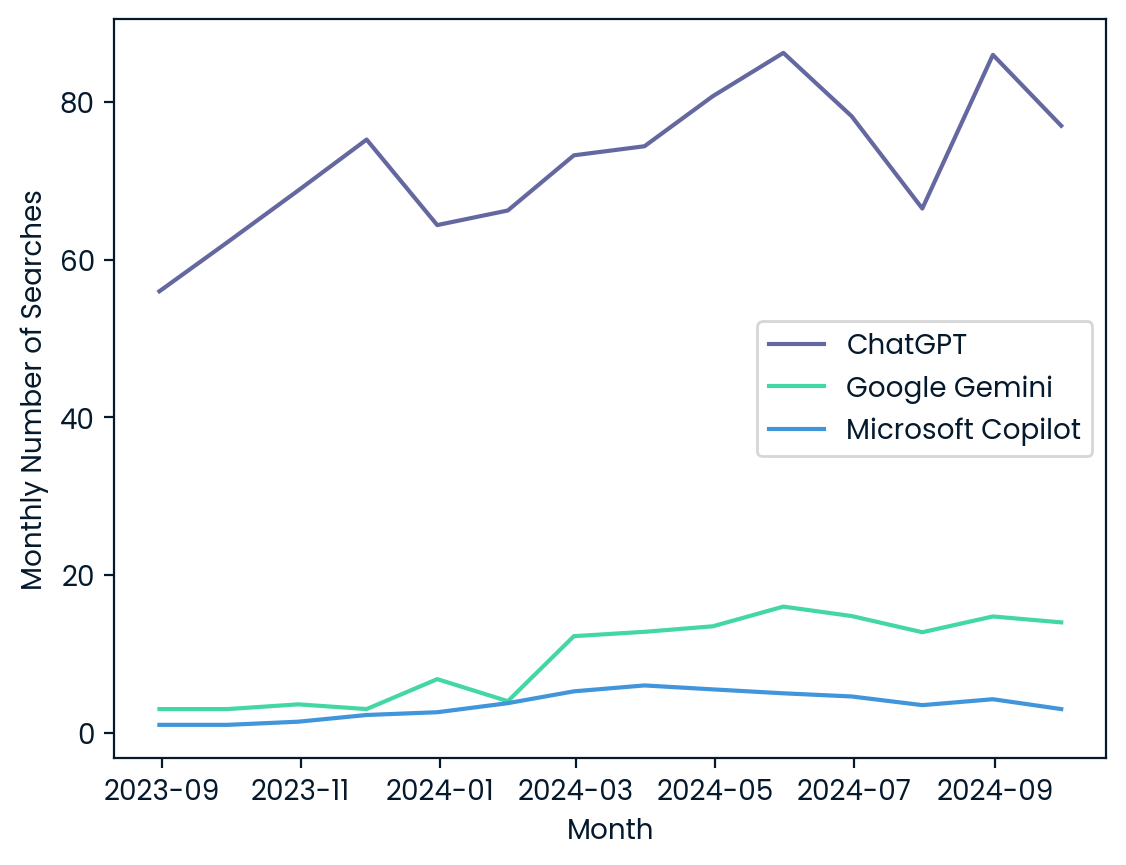

In [88]:
sns.lineplot(data=monthly_trends, x='month', y='chatgpt', label='ChatGPT')
sns.lineplot(data=monthly_trends, x='month', y='gemini', label='Google Gemini')
sns.lineplot(data=monthly_trends, x='month', y='microsoft_copilot', label='Microsoft Copilot')
plt.xlabel('Month')
plt.ylabel('Monthly Number of Searches')
plt.legend()
plt.show()

Let's add a column for the cumulative average of all tools.

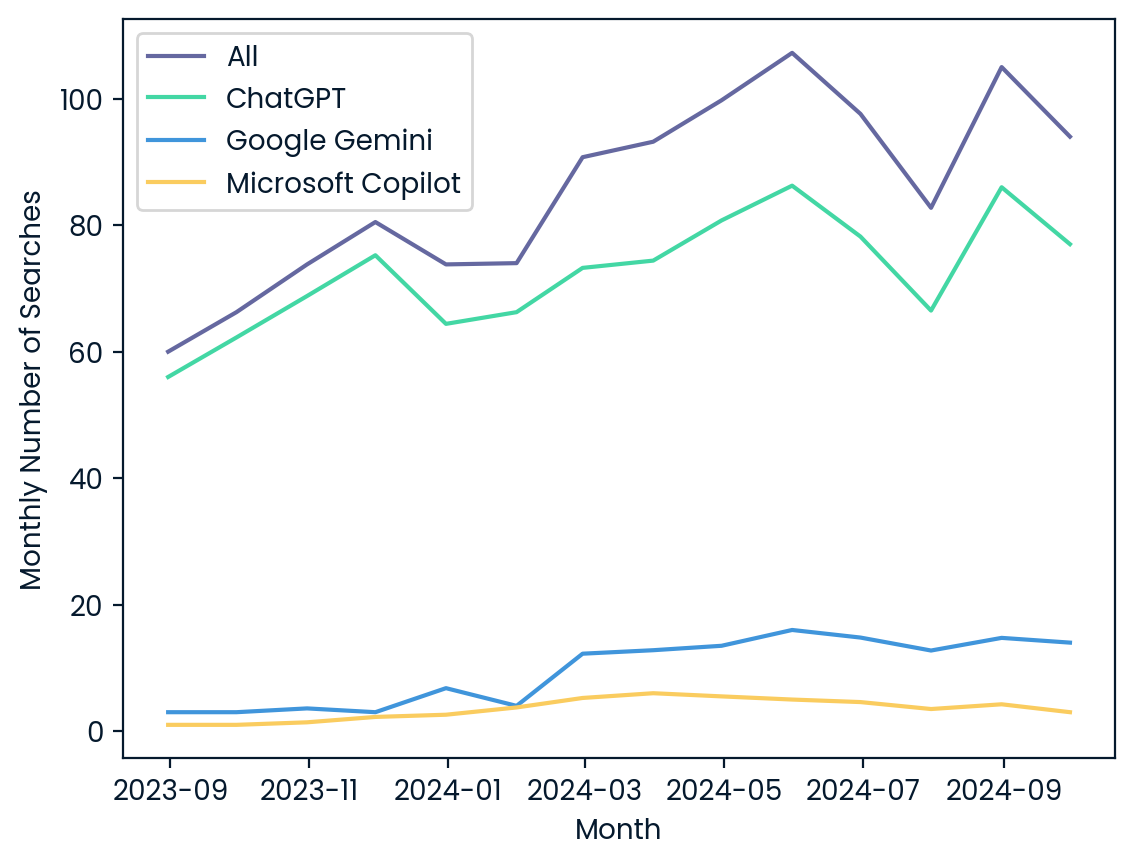

In [89]:
monthly_trends['cumulative'] = monthly_trends['chatgpt'] + monthly_trends['gemini'] + monthly_trends['microsoft_copilot']

sns.lineplot(data=monthly_trends, x='month', y='cumulative', label='All')
sns.lineplot(data=monthly_trends, x='month', y='chatgpt', label='ChatGPT')
sns.lineplot(data=monthly_trends, x='month', y='gemini', label='Google Gemini')
sns.lineplot(data=monthly_trends, x='month', y='microsoft_copilot', label='Microsoft Copilot')
plt.xlabel('Month')
plt.ylabel('Monthly Number of Searches')
plt.legend()
plt.show()

Here we see that the highest average interest across all tools was somewhere between 2024-05 and 2024-07. Let's find out more precisely.

In [90]:
best_month_amt = monthly_trends['cumulative'].max()
best_month_row = monthly_trends.loc[monthly_trends['cumulative'] == best_month_amt]
best_month = f'{best_month_row.index[0]:%B}'
print(best_month)

May


The highest average interest across all tools was in May 2024.